In [111]:
# !pip install catboost

In [112]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

try:
    from catboost import CatBoostClassifier
    cat_model = CatBoostClassifier(random_state=42, verbose=0)
except ModuleNotFoundError:
    print("CatBoost not installed; using HistGradientBoostingClassifier instead.")
    cat_model = HistGradientBoostingClassifier(random_state=42)

warnings.filterwarnings("ignore")

In [113]:
# 1. Load and inspect the dataset
data = pd.read_csv("Breast_cancer_dataset.csv")
print("Shape:", data.shape)
print(data["diagnosis"].value_counts())

Shape: (569, 33)
diagnosis
B    357
M    212
Name: count, dtype: int64


In [114]:
# Drop 'id' if present and remove any completely empty columns
data = data.drop(columns=["id"], errors="ignore").dropna(axis=1, how="all")


In [115]:
# 2. Encode target variable ('B' -> 0, 'M' -> 1)
label_encoder = LabelEncoder()
data["diagnosis"] = label_encoder.fit_transform(data["diagnosis"])

In [116]:
# 3. Split into features and target
X = data.drop(columns=["diagnosis"])
y = data["diagnosis"]

In [117]:
# Split into training and testing sets (stratified to preserve class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [118]:
# 4. Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [119]:
# 5. Define models
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Support Vector Machine": SVC(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss"),
    "CatBoost": cat_model,
}

In [120]:
# 6. Train and evaluate each model
results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results.append({"Model": name, "Accuracy": accuracy})

    print(f"Accuracy of {name}: {accuracy:.4f}")
    print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("=" * 60)

Training Logistic Regression...
Accuracy of Logistic Regression: 0.9649
              precision    recall  f1-score   support

           B       0.96      0.99      0.97        72
           M       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Confusion Matrix:
 [[71  1]
 [ 3 39]]
Training Random Forest...
Accuracy of Random Forest: 0.9737
              precision    recall  f1-score   support

           B       0.96      1.00      0.98        72
           M       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

Confusion Matrix:
 [[72  0]
 [ 3 39]]
Training Gradient Boosting...
Accuracy of Gradient Boosting: 0.9649
              precision    recall  f1-score   support

           B   

                    Model  Accuracy
0           Random Forest  0.973684
1                 XGBoost  0.973684
2  Support Vector Machine  0.973684
3     Logistic Regression  0.964912
4       Gradient Boosting  0.964912
5                CatBoost  0.964912
6     K-Nearest Neighbors  0.956140
7           Decision Tree  0.929825
8             Naive Bayes  0.921053


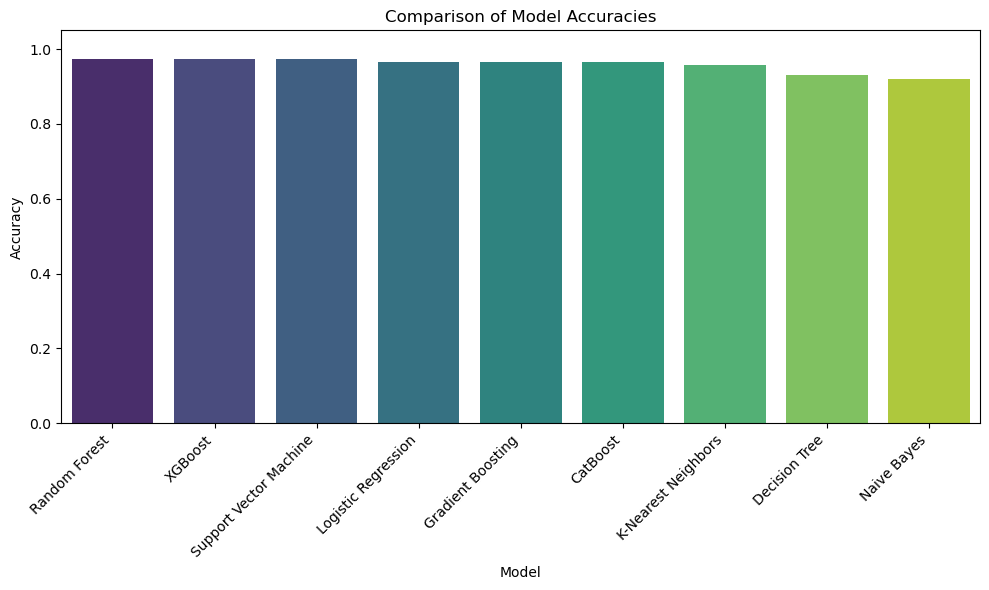

In [121]:
# 7. Compare model accuracies in a DataFrame and bar plot
results_df = (
    pd.DataFrame(results)
    .sort_values(by="Accuracy", ascending=False)
    .reset_index(drop=True)
)
print(results_df)

plt.figure(figsize=(10, 6))
sns.barplot(x="Model", y="Accuracy", data=results_df, palette="viridis")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Comparison of Model Accuracies")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()